# CC0F4 · PC3 — De un sistema RAG evaluable a workflows, agentes controlados y memoria verificable
**Pedro Lautaro Quispe Ballesteros** · Semanas 9 y 10 (con reutilización de las semanas 4, 6 y 7) · modalidad individual.
Tema (PC1 → PC2 → parcial → PC3): *Sistema multiagente con RAG híbrido para la detección temprana de riesgo de mercado con alertas
sustentadas en evidencia*.

**Tarea multi-paso.** Dada una pregunta sobre un activo y una fecha: (1) recuperar evidencia del episodio con el recuperador **C** del
parcial, (2) calcular la señal con la herramienta `risk.compute_signal` del parcial, (3) contrastar señal y evidencia y (4) decidir
`alert`, `no_alert` o `abstain` con una respuesta estructurada y verificable.

```text
Exp. 1   mismas 15 tareas, mismo controlador, mismas herramientas y límites
         W0 = workflow fijo (reglas, sin LLM)      vs      W1 = agente Qwen2.5-0.5B que elige la acción y cuándo parar
Exp. 2   mismo agente W1, 3 secuencias encadenadas (9 interacciones, 7 sesiones)
         M0 sin memoria | M1 working | M2 episódica (JSONL) | M3 semántica (e5 + FAISS, versión e invalidación)
         + diagnóstico sin LLM (lector determinista) para separar la calidad de la memoria de la del modelo
```

**Continuidad.** El parcial dejó corpus (21 documentos, 150 passages), qrels, el recuperador C (e5 + FAISS + BM25 + RRF +
Cross-Encoder) y la herramienta con contratos que reproduce los 8 casos de la PC1. Aquí se **importan** desde `../parcial/src` sin
modificarlos (`src/config.py`). La PC1 ya mostró que un LLM de 0.5B no aplica la regla de riesgo; la PC3 pregunta si ese mismo
modelo puede, al menos, **coordinar** las herramientas que hacen el cálculo.

**Cómo ejecutar:** `docker compose up` en `pc3/` → <http://localhost:8891/lab>. Este cuaderno **no** vuelve a correr los
experimentos (Qwen en CPU tarda ~1 h): carga las trazas y los CSV originales de `results/`, ejecuta las 20 pruebas y una demostración
corta. Comandos para regenerar todo: `README.md` §14.

In [1]:
import os; os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"; os.environ["TRANSFORMERS_NO_ADVISORY_WARNINGS"] = "1"
import json, sys, subprocess, platform, warnings; warnings.filterwarnings("ignore")
from transformers.utils import logging as hf_logging; hf_logging.disable_progress_bar(); hf_logging.set_verbosity_error()
from pathlib import Path
ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
import pandas as pd
pd.set_option("display.max_colwidth", 120); pd.set_option("display.width", 200)
from IPython.display import display, Image, Markdown
from config import *                      # rutas, LIMITS, STOP_REASONS (y parcial/src en el path)
cfg = json.loads((RESULTS / "declared_config.json").read_text(encoding="utf-8"))
print("python", platform.python_version(), "| declarado:", cfg["declared_at_utc"], "| LLM:", cfg["llm"]["id"], cfg["llm"]["decoding"])

python 3.12.16 | declarado: 2026-11-12T17:12:35+00:00 | LLM: Qwen/Qwen2.5-0.5B-Instruct {'do_sample': False, 'max_new_tokens': 200, 'repetition_penalty': 1.05}


## 1. Límites y condiciones de terminación (fijados antes de ejecutar)

El controlador es **código**, no el LLM. Comprueba los presupuestos antes de cada decisión, valida la acción propuesta contra una
*allowlist* y su contrato, ejecuta la herramienta con timeout, valida la observación antes de que entre al contexto, detecta
repeticiones y falta de progreso, y valida la respuesta final contra lo observado. Los límites y las definiciones se escribieron en
`results/declared_config.json` antes de la primera corrida evaluada, junto con los hashes del benchmark, los prompts, el corpus y los
precios; la celda comprueba que no cambiaron.

In [2]:
display(pd.DataFrame([{"limite": k, "valor": v} for k, v in cfg["limits"].items()]))
display(pd.DataFrame([{"stop_reason": k, "definicion verificable": v} for k, v in cfg["stop_reasons"].items()]))
same = cfg["data_hashes"] == data_hashes()
print("benchmark, prompts, corpus y precios sin cambios desde la declaracion:", same)

,limite,valor
0,max_steps,6.0
1,max_tool_calls,5.0
2,max_invalid_outputs,2.0
3,max_tool_errors,2.0
4,no_progress_patience,2.0
5,timeout_per_tool_s,20.0
6,total_deadline_s,300.0
7,max_input_tokens,2048.0
8,max_output_tokens,200.0
9,max_passages_per_search,6.0


,stop_reason,definicion verificable
0,SUCCESS,finish aceptado con decision alert/no_alert: ids de evidencia observados y severidad igual a una senal observada o a...
1,ABSTAIN,finish aceptado con decision abstain (el sistema declara que no puede sustentar una conclusion)
2,MAX_STEPS,se alcanzo max_steps o max_tool_calls sin un finish aceptado
3,TIMEOUT,se excedio total_deadline_s o una herramienta excedio su tiempo (timeout_per_tool_s o el deadline interno)
4,TOOL_ERROR,max_tool_errors errores de herramienta consecutivos sin un finish
5,INVALID_OUTPUT,"max_invalid_outputs decisiones invalidas (JSON no parseable, accion fuera de la allowlist, argumentos o finish que n..."
6,NO_PROGRESS,"no_progress_patience acciones ejecutadas seguidas que no anaden passages, senales ni recuerdos nuevos"
7,REPEATED_ACTION,la politica propone exactamente una accion (nombre + argumentos) ya ejecutada en la tarea


benchmark, prompts, corpus y precios sin cambios desde la declaracion: True


## 2. Benchmark de tareas (15) y escenarios de memoria (9 interacciones)

Las respuestas esperadas **no salen de W0 ni de W1**: la severidad se calcula con la regla de la PC1 (la misma que reproduce los 8 casos
gold) y la evidencia aceptable es el conjunto de passages del corpus que describen el episodio, anotado leyendo su texto
(`src/build_tasks.py`, `data/evidence_sets.json`; T08 reutiliza los qrels de Q01 del parcial). Tipos: **8 ordinarias** (≥ 2
operaciones; T07 compara dos activos), **4 con fallo de herramienta** (T09 es un error real de dominio: el 15-mar-2020 fue domingo;
T10–T12 son fallos **inyectados** y así se rotulan) y **3 de abstención o rechazo** (activo sin datos, fecha fuera de rango y una
afirmación falsa de un colega). Cada tarea trae objetivo, entrada, operaciones, fuentes permitidas, resultado esperado, criterio de
éxito y terminaciones permitidas.

In [3]:
tasks = read_jsonl(DATA / "tasks.jsonl"); expected = {e["task_id"]: e for e in read_jsonl(DATA / "expected_results.jsonl")}
display(pd.DataFrame([{"task_id": t["task_id"], "tipo": t["category"], "objetivo": t["objective"],
    "entrada": "; ".join(f'{r["ticker"]} {r["as_of"]}' for r in t["input"]["signal_requests"]),
    "operaciones": " -> ".join(t["operations"]), "fallo inyectado": (t["injected_fault"] or {}).get("note", ""),
    "esperado": f'{expected[t["task_id"]]["decision"]} {expected[t["task_id"]]["ticker"] or ""} {expected[t["task_id"]]["as_of"] or ""} {expected[t["task_id"]]["severity"] or ""}',
    "evidencia": expected[t["task_id"]]["evidence_set"] or "-", "stops permitidos": "/".join(expected[t["task_id"]]["allowed_stops"])}
    for t in tasks]))

,task_id,tipo,objetivo,entrada,operaciones,fallo inyectado,esperado,evidencia,stops permitidos
0,T01,ordinary,Alerta sustentada en el crash del COVID-19,SPY 2020-03-16,search_evidence -> compute_signal -> contrast -> finish,,alert SPY 2020-03-16 high,covid_2020,SUCCESS
1,T02,ordinary,Alerta sustentada tras la quiebra de SVB,SPY 2023-03-13,search_evidence -> compute_signal -> contrast -> finish,,alert SPY 2023-03-13 medium,svb_2023,SUCCESS
2,T03,ordinary,Alerta sustentada en el unwind del carry trade,SPY 2024-08-05,search_evidence -> compute_signal -> contrast -> finish,,alert SPY 2024-08-05 medium,carry_2024,SUCCESS
3,T04,ordinary,Alerta sustentada para small caps en 2022,IWM 2022-06-13,search_evidence -> compute_signal -> contrast -> finish,,alert IWM 2022-06-13 high,rates_2022,SUCCESS
4,T05,ordinary,Alerta sustentada en el shock arancelario de 2025,SPY 2025-04-08,search_evidence -> compute_signal -> contrast -> finish,,alert SPY 2025-04-08 high,tariffs_2025,SUCCESS
5,T06,ordinary,No emitir alerta en un periodo tranquilo,GLD 2019-04-30,search_evidence -> compute_signal -> contrast -> finish,,no_alert GLD 2019-04-30 low,-,SUCCESS
6,T07,ordinary,Contrastar dos activos y alertar el de mayor senal,SPY 2023-03-13; IWM 2023-03-13,search_evidence -> compute_signal x2 -> contrast -> finish,,alert IWM 2023-03-13 high,svb_2023,SUCCESS
7,T08,ordinary,Alerta con una evidencia especifica (record del VIX),SPY 2020-03-16,search_evidence (posible reformulacion) -> compute_signal -> contrast -> finish,,alert SPY 2020-03-16 high,vix_record_2020,SUCCESS
8,T09,tool_failure,Recuperarse de un error de dominio (fecha no habil),SPY 2020-03-15,search_evidence -> compute_signal -> ERROR date_not_trading_day -> compute_signal (2020-03-13) -> finish,,alert SPY 2020-03-13 high,covid_2020,SUCCESS
9,T10,tool_failure,Fuente de precios caida (fallo transitorio que no se recupera),SPY 2022-06-13,search_evidence -> compute_signal -> ERROR transient (reintentos agotados) -> abstain,INYECTADO: la fuente falla en todos los intentos,abstain,-,ABSTAIN/TOOL_ERROR


In [4]:
mem = read_jsonl(DATA / "memory_scenarios.jsonl")
display(pd.DataFrame([{"id": m["task_id"], "sesion": m["session"], "pregunta": m["input"]["question"][:95],
    "esperado": f'{m["expected"]["decision"]} {m["expected"]["ticker"]} {m["expected"]["as_of"]} {m["expected"]["severity"]}',
    "flags": ",".join(k for k, v in m["flags"].items() if v) or "-", "recuerdo correcto": ",".join(m["gold_memory_sources"]) or "-",
    "obsoleto / interferente": ",".join(m["stale_sources"] + m["interfering_sources"]) or "-"} for m in mem]))

,id,sesion,pregunta,esperado,flags,recuerdo correcto,obsoleto / interferente
0,S1-1,A,"Should a market-risk alert be issued for SPY on 2023-03-13, right after the failure of Silicon",alert SPY 2023-03-13 medium,-,-,-
1,S1-2,A,Report again the alert you issued earlier in this session for SPY during the Silicon Valley Ban,alert SPY 2023-03-13 medium,needs_memory,S1-1,-
2,S1-3,B,In an earlier session an alert was issued for SPY during the Silicon Valley Bank failure. Which,alert SPY 2023-03-13 medium,"needs_memory,cross_session",S1-1,-
3,S2-1,C,"Should a market-risk alert be issued for SPY on 2024-08-05, during the carry trade unwind? Supp",alert SPY 2024-08-05 medium,-,-,-
4,S2-2,D,Scenario update: it is now 2024-08-30. Re-evaluate the SPY alert from the August 2024 carry tra,no_alert SPY 2024-08-30 low,stale_risk,-,S2-1
5,S2-3,E,"What is the current status of the SPY alert from the August 2024 carry trade unwind, according",no_alert SPY 2024-08-30 low,"needs_memory,cross_session,stale_risk",S2-2,S2-1
6,S3-1,F,"Should a market-risk alert be issued for SPY on 2020-03-16, during the COVID-19 crash? Support",alert SPY 2020-03-16 high,-,-,-
7,S3-2,F,"Should a market-risk alert be issued for SPY on 2025-04-08, after the April 2025 tariff announc",alert SPY 2025-04-08 high,-,-,-
8,S3-3,G,Which date and severity did the SPY alert issued during the COVID-19 crash have?,alert SPY 2020-03-16 high,"needs_memory,cross_session,interference",S3-1,S3-2


## 3. Arquitectura: qué decide el LLM y qué decide el controlador

| Decide | W0 workflow | W1 agente | Controlador (ambos) |
|---|---|---|---|
| Siguiente acción y argumentos | plan fijo: buscar con la pregunta → señal de cada par pedido | **el LLM** (JSON con `action`, `arguments`, `reason`) | rechaza acciones fuera de la allowlist o que no cumplen el contrato |
| Cuándo terminar | después del plan | **el LLM** (`finish`) | corta por `max_steps`, `max_tool_calls`, deadline, errores, repetición o falta de progreso |
| Respuesta | regla: severidad ≥ medium → `alert`; low → `no_alert`; error → `abstain` | **el LLM** | acepta solo si la severidad coincide con una señal observada (o un recuerdo citado) y los ids de evidencia fueron vistos |
| Ejecución de herramientas | — | — | siempre el controlador, con timeout; el modelo nunca ejecuta código |

**Herramientas** (`src/tools.py`): `search_evidence(query, top_k≤5)` = recuperador C del parcial (Semanas 4, 5 y 7);
`compute_signal(ticker, as_of)` = `risk.compute_signal` del parcial con sus contratos, reintentos y timeout (Semana 6);
`read_passage(passage_id)` = operación auxiliar nueva, solo para passages ya vistos. Cada observación pasa por un modelo Pydantic:
el texto se trunca y se limpia, los ids se comprueban contra el corpus y los errores llegan al modelo **solo como campos**
(`kind`, `code`, `retryable`), nunca como mensaje libre. Así un fallo no se convierte en una instrucción.

**ReAct acotado.** El campo `reason` (≤ 20 palabras) es el «pensamiento» que queda en la traza; se intercala con la acción y la
observación. No hay planificador separado: el plan de W1 es implícito, paso a paso; el *replanning* posible es reformular una
búsqueda o corregir una fecha tras un error (T09). El prompt se ajustó en 3 versiones **solo** con dos tareas de desarrollo que no
están en el benchmark (`data/dev_tasks.jsonl`, `results/dev/v1..v3`); la v3 quedó congelada antes de las corridas evaluadas.

In [5]:
print((PROMPTS / "agent_system.txt").read_text(encoding="utf-8"))
print("---- plantilla del turno ----")
print((PROMPTS / "agent_user.txt").read_text(encoding="utf-8"))

You are the controller of a market-risk alert check. At each step you choose ONE action and reply with ONE JSON object only, no other text.

Allowed actions (exact argument names, nothing else inside "arguments"):
{"action": "search_evidence", "arguments": {"query": "<event words, 3+ characters>", "top_k": 3}, "reason": "<why, max 20 words>"}
{"action": "compute_signal", "arguments": {"ticker": "<TICKER>", "as_of": "YYYY-MM-DD"}, "reason": "<why>"}
{"action": "read_passage", "arguments": {"passage_id": "<id already seen>"}, "reason": "<why>"}
{"action": "finish", "arguments": {"decision": "alert | no_alert | abstain", "ticker": "<TICKER>", "as_of": "YYYY-MM-DD", "severity": "low | medium | high", "evidence_ids": ["<passage ids>"], "memory_ids": ["<memory ids used>"]}, "reason": "<why>"}

Rules:
- compute_signal returns the severity. Never put a severity inside compute_signal and never guess it.
- In finish, copy the severity from a compute_signal observation or from a MEMORY item.
- de

**Pruebas** (`tests/`, sin LLM): cada `stop_reason` tiene una prueba con una política guionizada; también se prueban la validación de la
respuesta final, que los errores no filtren el mensaje, la memoria (escritura, persistencia, invalidación y borrado) y las métricas.

In [6]:
r = subprocess.run([sys.executable, "-m", "pytest", "tests", "-q", "-p", "no:cacheprovider", "--color=no"], cwd=ROOT, capture_output=True, text=True)
print(r.stdout[-1500:])

....................                                                     [100%]
20 passed in 5.24s



## 4. Experimento 1 — Workflow determinista (W0) frente a agente controlado (W1)

**Pregunta.** ¿Permitir que un LLM seleccione herramientas y decida el siguiente paso aumenta el éxito en tareas multi-paso respecto de un
workflow fijo? **Hipótesis (declarada antes):** con un modelo de 0.5B, W1 no supera a W0 en éxito y cuesta más; podría ayudar solo donde
el plan fijo no se adapta (T08, reformular la búsqueda; T09, corregir la fecha). **Fijo:** benchmark, corpus, recuperador C,
herramientas y contratos, controlador y límites, modelo y decoding (greedy), sin memoria. **Variable:** la política que elige la
secuencia de acciones.

In [7]:
per1 = pd.read_csv(RESULTS / "exp1" / "per_task.csv"); sum1 = pd.read_csv(RESULTS / "exp1" / "summary.csv")
display(sum1.round(3))
piv = per1.pivot(index="task_id", columns="policy", values=["task_success", "stop_reason", "steps", "tool_calls", "tokens"])
display(piv)
display(per1.groupby(["policy", "category"]).task_success.agg(["mean", "sum", "count"]).round(2))

,policy,tasks,task_success,termination_correct,steps_mean,tool_calls_mean,tool_errors_total,invalid_outputs_total,repeated_actions_total,latency_ms_mean,latency_ms_median,prompt_tokens_total,output_tokens_total,tokens_mean_per_task,max_context_tokens
0,W0_workflow,15,0.800,0.933,3.067,2.067,5,0,0,1811.28,1765.9,0,0,0.000,0
1,W1_agent_qwen,15,0.067,0.067,2.867,1.867,4,0,14,38274.78,36722.5,43218,2077,3019.667,1545


task_success               stop_reason                        steps                tool_calls                    tokens              
policy   W0_workflow W1_agent_qwen W0_workflow    W1_agent_qwen W0_workflow W1_agent_qwen W0_workflow W1_agent_qwen W0_workflow W1_agent_qwen
task_id                                                                                                                                      
T01             True         False     SUCCESS  REPEATED_ACTION           3             2           2             1           0          2064
T02             True          True     SUCCESS          SUCCESS           3             3           2             2           0          3158
T03             True         False     SUCCESS  REPEATED_ACTION           3             4           2             3           0          4608
T04            False         False     SUCCESS  REPEATED_ACTION           3             4           2             3           0          5045
T05             True         False     SUCCESS  REPEATED_ACTION           3             4           2             3           0          4660
T06             True         False     SUCCESS  REPEATED_ACTION           3             2           2             1           0          1615
T07             True         False     SUCCESS  REPEATED_ACTION           4             3           3             2           0          2671
T08            False         False     SUCCESS  REPEATED_ACTION           3             2           2             1           0          1575
T09            False         False     ABSTAIN  REPEATED_ACTION           3             2           2             1           0          1984
T10             True         False     ABSTAIN  REPEATED_ACTION           3             2           2             1           0          1951
T11             True         False     ABSTAIN  REPEATED_ACTION           3             3           2             2           0          3175
T12             True         False     SUCCESS  REPEATED_ACTION           3             4           2             3           0          4825
T13             True         False     ABSTAIN  REPEATED_ACTION           3             3           2             2           0          3041
T14             True         False     ABSTAIN  REPEATED_ACTION           3             3           2             2           0          3301
T15             True         False     SUCCESS  REPEATED_ACTION           3             2           2             1           0          1622

mean  sum  count
policy        category                      
W0_workflow   abstain       1.00    3      3
              ordinary      0.75    6      8
              tool_failure  0.75    3      4
W1_agent_qwen abstain       0.00    0      3
              ordinary      0.12    1      8
              tool_failure  0.00    0      4

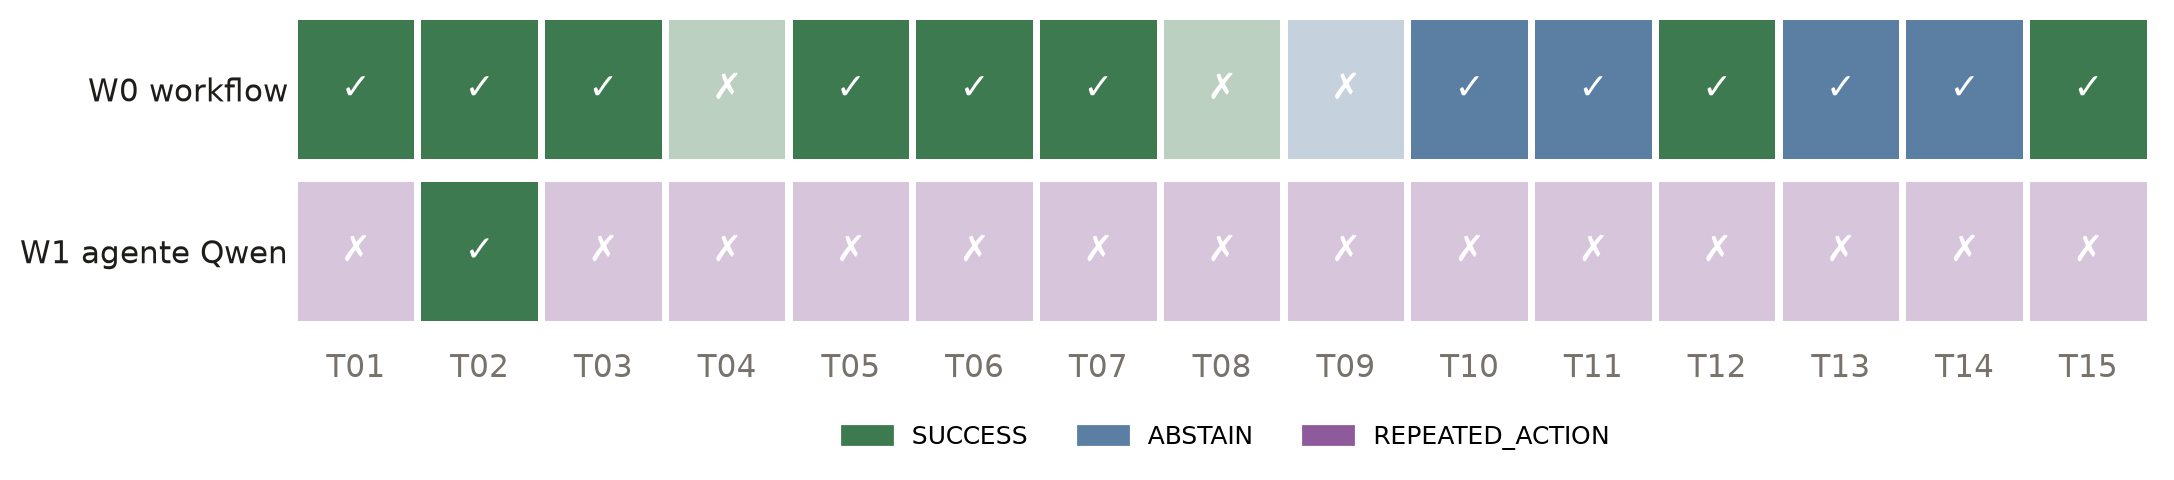

In [8]:
Image(filename=str(ROOT / "slides" / "fig" / "exp1_matriz.png"))

**Resultados.** W0 resuelve **12 de 15** (0,80) con 0 tokens y ~1,8 s por tarea. W1 resuelve **1 de 15** (0,07, solo T02) con
~3 020 tokens y ~38 s por tarea (contexto máximo de 1 545 tokens, por debajo del presupuesto de 2 048). En **14 tareas** el controlador
detuvo a W1 con `REPEATED_ACTION`: el modelo volvió a proponer exactamente una acción ya ejecutada (una búsqueda, una señal o la
lectura del mismo passage). W1 no emitió **ninguna** alerta falsa: en las 4 tareas en las que correspondía abstenerse (T10, T11, T13
y T14) no respondió, aunque terminó por repetición y no por `ABSTAIN`, así que `termination_correct` es 0 en esas tareas.

**El agente avanza pero no cierra.** W1 observó la señal correcta en 8 de las 11 tareas que la requerían (W0 en 10) y vio evidencia
del episodio en 7 de 9 (W0 en 8). Lo que falla es decidir que ya terminó: en DEV1 (desarrollo) incluso propuso `alert` con una señal
`low` y el controlador lo rechazó (`finish_alert_on_low_signal`).

Trazas originales de los casos que pide el enunciado:
* **Donde W1 mejora un paso que W0 hace mal: T04.** W0 busca con la pregunta completa y el ranking pone primero a SVB (D17, D03);
  como el workflow no juzga la pertinencia, cita `D17-P03, D17-P04, D03-P04` y falla la evidencia. W1 reformula
  («small caps IWM 2022 interest rate increases market decline») y recupera `D02-P01…P04`, que sí describen el 2022. Pero después lee
  `D02-P01` dos veces y se detiene: **mejor recuperación, mismo resultado final (fallo)**.
* **Donde W1 no mejora y cuesta más: T09.** El enunciado pide usar el día hábil anterior si la fecha no lo es. W0 recibe el error real
  `date_not_trading_day` y se abstiene (falla, pero de forma segura). W1 ni siquiera llega a pedir la señal: repite la misma búsqueda y
  se detiene a los 2 pasos (25,7 s, 1 984 tokens). Una regla de una línea en el workflow («si `date_not_trading_day`, usar el día hábil
  previo») resolvería T09 sin LLM.
* **Único éxito de W1: T02** — buscar, calcular y terminar con evidencia `D04-P01…P06`, igual que W0 pero ~28 veces más lento (48,4 s frente a 1,7 s).
* **T08** muestra el riesgo de un plan fijo: W0 busca y cita `D06-P03…P05` (definición del VIX), no el récord de 82,69; W1 inventa el
  id `P01-01`, que el contrato rechaza (`input_contract`), y lo repite.

In [9]:
def show_trace(folder, name):
    r = json.loads((TRACES / folder / f"{name}.json").read_text(encoding="utf-8"))
    print(f'{name}: stop={r["stop_reason"]} ({r["stop_detail"]}) answer={r["answer"]}')
    for t in r["trace"]:
        obs = t.get("observation")
        print(f'  step {t["step"]} [{t["decision_status"]}] {t["selected_tool"]} {json.dumps(t["arguments"])[:110]}')
        if t.get("reason"): print(f'      reason: {t["reason"][:120]}')
        print(f'      obs: {json.dumps(obs)[:150] if obs else t.get("error")} | tokens={t["tokens"]} latency_ms={t["latency_ms"]}')
    print()

In [10]:
for name in ["W0_workflow__T04", "W1_agent_qwen__T04", "W0_workflow__T09", "W1_agent_qwen__T09", "W1_agent_qwen__T02"]:
    show_trace("exp1", name)
# progreso parcial: ¿la politica llego a observar la senal esperada y evidencia del episodio?
rows = []
for pol in ["W0_workflow", "W1_agent_qwen"]:
    for t, e in expected.items():
        r = json.loads((TRACES / "exp1" / f"{pol}__{t}.json").read_text(encoding="utf-8"))
        rows.append({"policy": pol, "task_id": t,
                     "senal_esperada_observada": None if not e["severity"] else any(s["ticker"] == e["ticker"] and s["as_of"] == e["as_of"] for s in r["signals"]),
                     "evidencia_vista": None if not e["evidence_any_of"] else bool(set(r["seen_passages"]) & set(e["evidence_any_of"]))})
prog = pd.DataFrame(rows); display(prog.groupby("policy")[["senal_esperada_observada", "evidencia_vista"]].agg(lambda x: f"{int(x.dropna().sum())}/{x.notna().sum()}"))

W0_workflow__T04: stop=SUCCESS () answer={'decision': 'alert', 'ticker': 'IWM', 'as_of': '2022-06-13', 'severity': 'high', 'evidence_ids': ['D17-P03', 'D17-P04', 'D03-P04'], 'memory_ids': [], 'rationale': 'rule: IWM 2022-06-13 severity high (score 6)'}
  step 1 [accepted] search_evidence {"query": "Should a market-risk alert be issued for small caps (IWM) on 2022-06-13, amid the 2022 interest rat
      reason: plan step 1: retrieve evidence for the question
      obs: {"passage_ids": ["D17-P03", "D17-P04", "D03-P04", "D03-P05", "D02-P01", "D02-P02"]} | tokens={'prompt': 0, 'output': 0} latency_ms=1742.0
  step 2 [accepted] compute_signal {"ticker": "IWM", "as_of": "2022-06-13"}
      reason: plan step 2: compute the requested signal
      obs: {"ticker": "IWM", "as_of": "2022-06-13", "severity": "high", "score": 6, "ret5_pct": -9.17, "vol20_pct": 34.14, "dd20_pct": -10.61, "attempts": 1} | tokens={'prompt': 0, 'output': 0} latency_ms=17.2
  step 3 [accepted] finish {"decision": "alert"

W1_agent_qwen__T02: stop=SUCCESS () answer={'decision': 'alert', 'ticker': 'SPY', 'as_of': '2023-03-13', 'severity': 'medium', 'evidence_ids': ['D04-P01', 'D04-P02', 'D04-P05', 'D04-P06'], 'memory_ids': [], 'rationale': ''}
  step 1 [accepted] search_evidence {"query": "Silicon Valley Bank failure 2023-03-13", "top_k": 3}
      reason: find evidence of the event
      obs: {"passage_ids": ["D04-P01", "D04-P02", "D04-P05", "D04-P06"]} | tokens={'prompt': 704, 'output': 50} latency_ms=13722.7
  step 2 [accepted] compute_signal {"ticker": "SPY", "as_of": "2023-03-13"}
      reason: get the signal for the input
      obs: {"ticker": "SPY", "as_of": "2023-03-13", "severity": "medium", "score": 3, "ret5_pct": -4.72, "vol20_pct": 15.79, "dd20_pct": -6.91, "attempts": 1} | tokens={'prompt': 1075, 'output': 45} latency_ms=14088.2
  step 3 [accepted] finish {"decision": "alert", "ticker": "SPY", "as_of": "2023-03-13", "severity": "medium", "evidence_ids": ["D04-P01"
      obs: None | tokens={'pr

,senal_esperada_observada,evidencia_vista
policy,,
W0_workflow,10/11,8/9
W1_agent_qwen,8/11,7/9


### Pruebas de robustez y terminación

Además de los fallos dentro del benchmark (T09 error real de dominio, T10 fuente caída, T11 salida inválida, T12 fallo transitorio que se
recupera con el reintento interno de la herramienta: `attempts = 2` en la traza), se ejecutaron 7 pruebas **guionizadas** sobre las
herramientas reales. No son ejecuciones de un LLM: comprueban que el controlador termina con el `stop_reason` correcto, conserva la
traza y no deja salir ninguna respuesta.

In [11]:
rob = pd.read_csv(RESULTS / "exp1" / "robustness.csv"); display(rob)

,probe,expected_stop,stop_reason,stop_detail,ok,answer_emitted,steps,tool_calls,tool_errors,trace_steps,latency_ms
0,R1_repeated_action,REPEATED_ACTION,REPEATED_ACTION,search_evidence,True,False,2,1,0,2,1721.3
1,R2_budget_exhausted,MAX_STEPS,MAX_STEPS,max_tool_calls,True,False,6,5,0,6,8178.9
2,R3_invalid_output,INVALID_OUTPUT,INVALID_OUTPUT,unparseable_output,True,False,2,0,0,2,0.1
3,R4_unsupported_finish,INVALID_OUTPUT,INVALID_OUTPUT,finish_severity_not_supported,True,False,2,0,0,2,0.1
4,R5_transient_errors,TOOL_ERROR,TOOL_ERROR,transient:source_unavailable_retries_exhausted,True,False,2,2,2,2,304.4
5,R6_no_progress,NO_PROGRESS,NO_PROGRESS,search_evidence,True,False,3,3,0,3,6357.9
6,R7_tool_timeout,TIMEOUT,TIMEOUT,timeout:attempt_timeout_retries_exhausted,True,False,2,2,2,2,3311.7


Las 7 terminan como se esperaba y ninguna emite respuesta. Junto con T10/T11 (W0 se abstiene; W1 no responde) muestran que un
error de herramienta **no** se transforma en una alerta aparentemente válida: la salida corrupta de T11 se detiene en el contrato de
salida (`output_contract`) y nunca llega a ser una «señal».

**Conclusión del Exp. 1 (acotada a 15 tareas y a un modelo de 0.5B).** Para esta tarea un workflow fijo es suficiente y mucho más
barato: 0,80 frente a 0,07 de éxito, ~21 veces menos latencia y cero tokens. La autonomía solo aportó en un paso intermedio (reformular
la consulta en T04) y no se tradujo en éxito. La ganancia potencial de un agente (reparar T09, buscar mejor en T04 y T08) se puede
obtener añadiendo ramas al workflow (*routing* ante códigos de error, una segunda búsqueda si la evidencia no menciona el evento). No
se puede afirmar nada sobre modelos mayores: no se probaron.

## 5. Experimento 2 — Estado y memoria del agente

**Pregunta.** ¿Qué mejora aporta cada mecanismo de memoria a tareas encadenadas y qué errores introduce? **Hipótesis:** M1 ayuda
solo dentro de una sesión; M2 y M3 permiten recuperar entre sesiones; M2, al guardar historia sin invalidarla, puede devolver un
recuerdo obsoleto (S2-3) o uno parecido pero equivocado (S3-3); M3 evita el obsoleto porque lo invalida.
**Fijo:** agente W1 (modelo, prompt, decoding), herramientas, controlador, límites, presupuesto de contexto (2 048 tokens, de los cuales
como máximo 450 para memoria y 3 recuerdos) y orden de las 9 interacciones. **Variable:** el mecanismo de memoria.

| | Qué guarda | Dónde | Cómo se recupera | Persistencia | Actualización / invalidación |
|---|---|---|---|---|---|
| Estado de ejecución (todas) | contadores, observaciones de **una** tarea | `RunState` en RAM | — | se descarta al terminar | — |
| **M1** working | resultado de cada tarea anterior **de la sesión** | lista en RAM | los 3 más recientes | se borra al cambiar de sesión | — |
| **M2** episódica | un episodio por tarea: tarea, acciones, observaciones validadas, resultado, errores, `stop_reason` | `episodic.jsonl` | relevancia léxica + recencia + importancia, min-max y suma (Park et al.) | sí, se relee del disco en cada sesión | no se invalida: es historia |
| **M3** semántica | un hecho por señal observada en una tarea con `SUCCESS`, con procedencia (herramienta, hash de precios, passages), versión y estado | `semantic.jsonl` + FAISS (e5) | similitud coseno sobre hechos **activos** | sí | una señal más reciente del mismo activo (≤ 120 días) marca la anterior `superseded`; deja de servirse pero se conserva para auditoría |

Escribe **el controlador** al terminar cada tarea, solo con campos validados: no se guardan prompts, salidas crudas ni el `rationale`
libre del modelo (privacidad y trazabilidad). Toda operación queda en `memory_ops.jsonl` sin contenido. El borrado (`delete`) está
implementado y probado. **Escenarios:** S1 recuperación en la misma sesión (S1-2) y desde otra sesión (S1-3); S2 actualización
controlada del escenario: la fecha avanza al 30-ago-2024 con precios reales, la alerta *medium* del 5-ago queda obsoleta (S2-2) y se
pregunta por su estado actual (S2-3); S3 interferencia entre dos alertas *high* de SPY (COVID y aranceles) (S3-3).
**Denominadores:** `memory_recall_accuracy` / 4 interacciones que necesitan memoria; `cross_session_retention` / 3;
`stale_memory_error_rate` / 2 con riesgo de obsoleto; `wrong_memory_use_rate` / interacciones en que el agente citó algún recuerdo.
Una respuesta correcta que no cita el recuerdo correcto **no** cuenta como recuperación de memoria.

In [12]:
per2 = pd.read_csv(RESULTS / "exp2" / "per_interaction.csv"); sum2 = pd.read_csv(RESULTS / "exp2" / "summary.csv")
display(sum2.round(3))
display(per2[["condition", "task_id", "session", "stop_reason", "task_success", "memory_shown", "memory_cited",
              "memory_recall_ok", "stale_error", "wrong_memory_use", "answer_as_of", "answer_severity", "max_context_tokens"]])

,condition,interactions,task_success,memory_recall_accuracy,n_needs_memory,gold_retrieved_at3,gold_retrieved_top1,cross_session_retention,n_cross_session,stale_memory_error_rate,n_stale_risk,wrong_memory_use_rate,n_cited_memory,context_tokens_mean,memory_tokens_mean,latency_ms_mean,steps_mean,tool_calls_mean
0,M0_none,9,0.222,0.0,4,0.00,0.00,0.0,3,0.0,2,NaN,0,1164.444,0.000,39910.878,2.778,1.778
1,M1_working,9,0.111,0.0,4,0.25,0.25,0.0,3,0.0,2,NaN,0,1104.333,23.444,35739.822,2.556,1.444
2,M2_episodic,9,0.111,0.0,4,1.00,0.50,0.0,3,0.0,2,NaN,0,1183.111,204.778,34438.511,2.444,1.333
3,M3_semantic,9,0.111,0.0,4,0.50,0.50,0.0,3,0.0,2,NaN,0,1187.778,136.889,44694.067,3.111,2.000


,condition,task_id,session,stop_reason,task_success,memory_shown,memory_cited,memory_recall_ok,stale_error,wrong_memory_use,answer_as_of,answer_severity,max_context_tokens
0,M0_none,S1-1,A,SUCCESS,True,NaN,NaN,False,False,False,2023-03-13,medium,1196
1,M0_none,S1-2,A,SUCCESS,True,NaN,NaN,False,False,False,2023-03-13,medium,1312
2,M0_none,S1-3,B,REPEATED_ACTION,False,NaN,NaN,False,False,False,NaN,NaN,1192
3,M0_none,S2-1,C,REPEATED_ACTION,False,NaN,NaN,False,False,False,NaN,NaN,1405
4,M0_none,S2-2,D,REPEATED_ACTION,False,NaN,NaN,False,False,False,NaN,NaN,766
5,M0_none,S2-3,E,REPEATED_ACTION,False,NaN,NaN,False,False,False,NaN,NaN,730
6,M0_none,S3-1,F,REPEATED_ACTION,False,NaN,NaN,False,False,False,NaN,NaN,1247
7,M0_none,S3-2,F,REPEATED_ACTION,False,NaN,NaN,False,False,False,NaN,NaN,1397
8,M0_none,S3-3,G,SUCCESS,False,NaN,NaN,False,False,False,2023-03-13,medium,1235
9,M1_working,S1-1,A,SUCCESS,True,NaN,NaN,False,False,False,2023-03-13,medium,1196


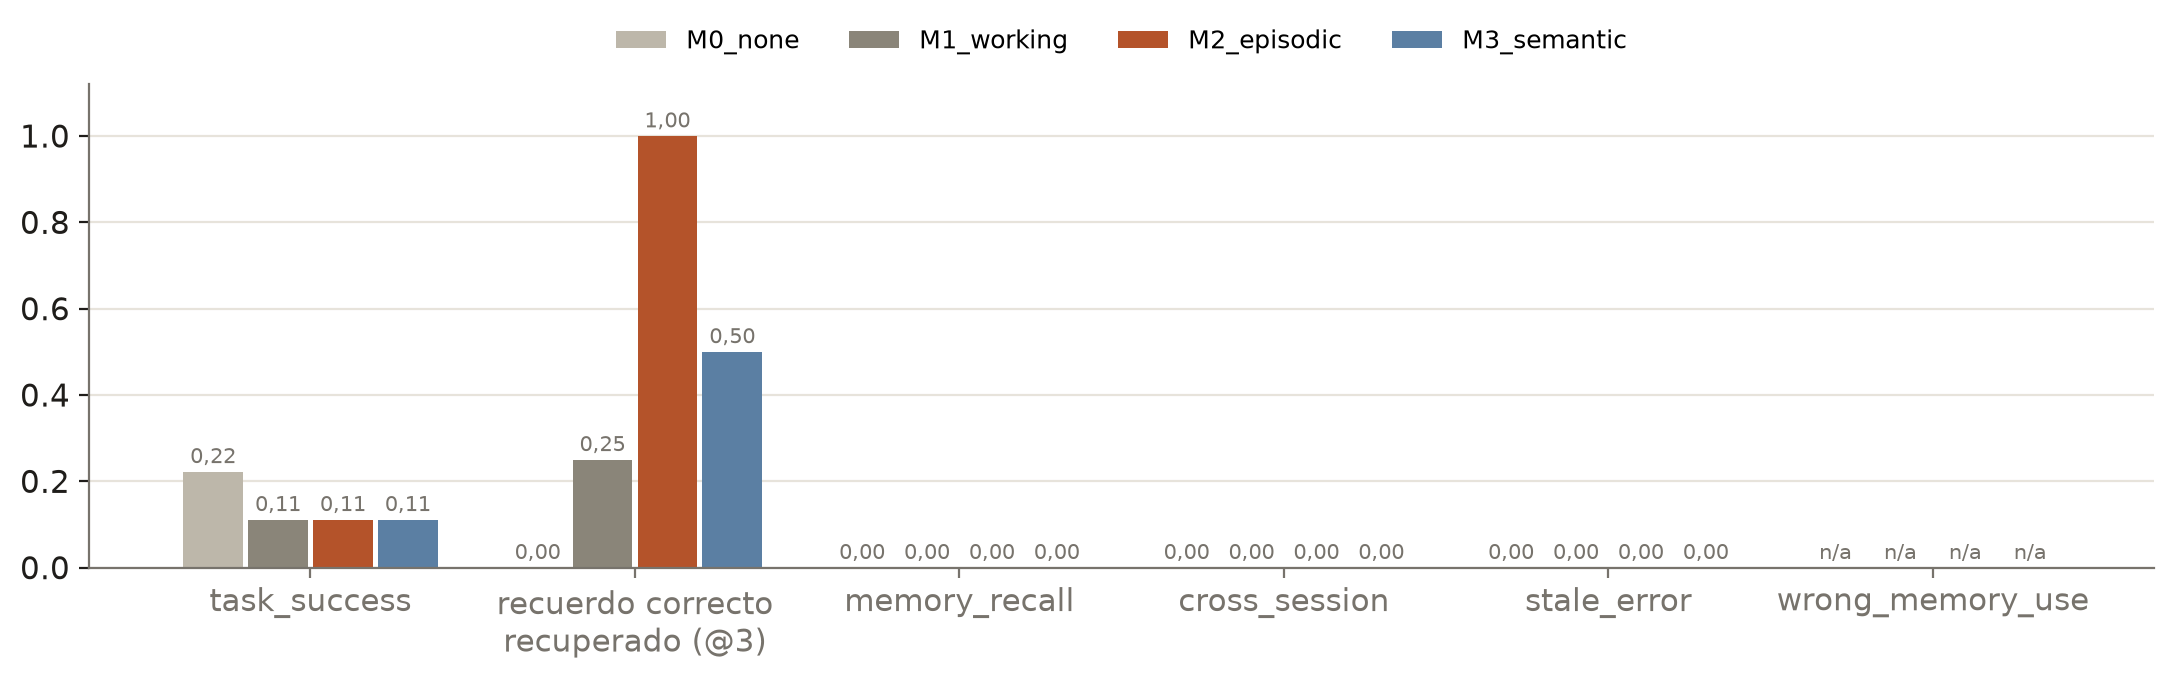

In [13]:
Image(filename=str(ROOT / "slides" / "fig" / "exp2_metricas_qwen.png"))

**Resultados con el agente Qwen (experimento oficial).** El éxito es 0,22 (M0), 0,11 (M1), 0,11 (M2) y 0,11 (M3), y
`memory_recall_accuracy` y `cross_session_retention` valen **0 en las cuatro**: el modelo **nunca** listó un recuerdo en
`memory_ids`. Que M0 «gane» no significa que la memoria estorbe. Su éxito extra es **S1-2 acertada por casualidad**: sin memoria, busca
«Silicon Valley Bank failure» y pide la señal del 2023-03-13, la misma fecha del ejemplo del prompt. La prueba está en **S3-3**:
también sin memoria, ante una pregunta sobre el COVID, vuelve a usar 2023-03-13 y responde mal. Por eso esos aciertos no cuentan como
recuperación.

La memoria **sí funcionó como recuperación**: el recuerdo correcto apareció entre los mostrados en 4/4 interacciones con M2, 2/4
con M3 y 1/4 con M1 (`gold_retrieved_at3`). M3 quedó casi vacía porque solo consolida tareas con `SUCCESS`, y el agente casi no las
tuvo: su única entrada (F001, SVB) se sirvió en todas las preguntas, pertinente o no. Es el costo de una política de escritura
conservadora con un agente débil. El consumo de contexto fue similar (≈ 1 100–1 190 tokens de prompt por interacción; memoria: 0, 23,
205 y 137 tokens de media).

In [14]:
for cond in ["M2_episodic", "M3_semantic"]:
    rows = read_jsonl(RESULTS / "exp2" / "memory_store" / cond / ("episodic.jsonl" if cond == "M2_episodic" else "semantic.jsonl"))
    display(Markdown(f"**{cond}** ({len(rows)} recuerdos persistidos)"))
    display(pd.DataFrame([{"id": m["memory_id"], "status": m["status"], "version": m["version"], "origen": m["provenance"]["interaction_id"],
        "sesion": m["provenance"]["session"], "superseded_by": m.get("superseded_by", ""), "texto": m["text"][:120]} for m in rows]))
ops = read_jsonl(RESULTS / "exp2" / "memory_store" / "M3_semantic" / "memory_ops.jsonl")
display(pd.Series([o["op"] for o in ops]).value_counts().rename("operaciones M3"))

**M2_episodic** (9 recuerdos persistidos)

,id,status,version,origen,sesion,superseded_by,texto
0,E001,active,1,S1-1,A,,"episode of task 'Should a market-risk alert be issued for SPY on 2023-03-13, right after the failure of Sil': SPY as..."
1,E002,active,1,S1-2,A,,episode of task 'Report again the alert you issued earlier in this session for SPY during the Silicon Valle': SPY as...
2,E003,active,1,S1-3,B,,episode of task 'In an earlier session an alert was issued for SPY during the Silicon Valley Bank failure. ': SPY as...
3,E004,active,1,S2-1,C,,"episode of task 'Should a market-risk alert be issued for SPY on 2024-08-05, during the carry trade unwind?': no sig..."
4,E005,active,1,S2-2,D,,episode of task 'Scenario update: it is now 2024-08-30. Re-evaluate the SPY alert from the August 2024 carr': SPY as...
5,E006,active,1,S2-3,E,,"episode of task 'What is the current status of the SPY alert from the August 2024 carry trade unwind, accor': SPY as..."
6,E007,active,1,S3-1,F,,"episode of task 'Should a market-risk alert be issued for SPY on 2020-03-16, during the COVID-19 crash? Sup': no sig..."
7,E008,active,1,S3-2,F,,"episode of task 'Should a market-risk alert be issued for SPY on 2025-04-08, after the April 2025 tariff an': SPY as..."
8,E009,active,1,S3-3,G,,episode of task 'Which date and severity did the SPY alert issued during the COVID-19 crash have?': SPY as of 2025-0...


**M3_semantic** (1 recuerdos persistidos)

,id,status,version,origen,sesion,superseded_by,texto
0,F001,active,1,S1-1,A,,"SPY risk signal as of 2023-03-13: severity medium (score 3; 5-day return -4.72%, 20-day volatility 15.79%, drawdown ..."


write    1
Name: operaciones M3, dtype: int64

In [15]:
for name in ["M0_none__S1-2", "M0_none__S3-3", "M2_episodic__S1-2", "M2_episodic__S2-3", "M2_episodic__S3-3"]:
    show_trace("exp2", name)
    r = json.loads((TRACES / "exp2" / f"{name}.json").read_text(encoding="utf-8"))
    print("   memoria mostrada:", [(m["memory_id"], m["provenance"]["interaction_id"], m.get("score")) for m in r["memory_shown"]], "\n")

M0_none__S1-2: stop=SUCCESS () answer={'decision': 'alert', 'ticker': 'SPY', 'as_of': '2023-03-13', 'severity': 'medium', 'evidence_ids': ['D04-P01', 'D04-P02', 'D17-P09', 'D17-P10', 'D04-P05', 'D04-P06'], 'memory_ids': [], 'rationale': ''}
  step 1 [accepted] search_evidence {"query": "Silicon Valley Bank failure", "top_k": 3}
      reason: find evidence of the event
      obs: {"passage_ids": ["D04-P01", "D04-P02", "D17-P09", "D17-P10", "D04-P05", "D04-P06"]} | tokens={'prompt': 679, 'output': 39} latency_ms=11244.4
  step 2 [accepted] compute_signal {"ticker": "SPY", "as_of": "2023-03-13"}
      reason: get the signal for the input
      obs: {"ticker": "SPY", "as_of": "2023-03-13", "severity": "medium", "score": 3, "ret5_pct": -4.72, "vol20_pct": 15.79, "dd20_pct": -6.91, "attempts": 1} | tokens={'prompt': 1191, 'output': 45} latency_ms=13843.7
  step 3 [accepted] finish {"decision": "alert", "ticker": "SPY", "as_of": "2023-03-13", "severity": "medium", "evidence_ids": ["D04-P01"
 

**Los tres casos que pide el enunciado, en las trazas del agente:**
* **La memoria ayuda (a un paso, no al resultado): S1-3 y S2-3.** Sin la fecha en la pregunta, con M2 el agente toma la fecha del
  recuerdo mejor rankeado y recalcula la señal correcta: 2023-03-13 en S1-3 (E001) y 2024-08-30, la vigente, en S2-3 (E005, primero
  por recencia). Sin memoria (M0), en esas mismas interacciones no tiene la fecha: repite una búsqueda (S1-3) o la lectura de un passage (S2-3) y se detiene. Luego vuelve a repetir la acción y no
  termina.
* **No mejora: S1-2 con M1 y M2.** El agente tiene el recuerdo y la fecha correcta, pero pone el id del recuerdo (`E001`) en
  `evidence_ids` en vez de en `memory_ids`; el controlador rechaza dos veces (`finish_unobserved_evidence`) y termina en
  `INVALID_OUTPUT`. El contrato protege la respuesta, pero el modelo no aprende el formato.
* **Recupera información equivocada: S3-3 con M2 (interferencia).** Para «la alerta de SPY durante el COVID», la memoria episódica pone
  primero E008 (aranceles 2025, más reciente) y la correcta E007 tercera. El agente usa la fecha equivocada: calcula 2025-04-08.

### Diagnóstico sin LLM: la misma memoria con un lector determinista (añadido después de ver la corrida con Qwen)

Como el modelo no usa la memoria, la corrida oficial no permite decir **qué memoria es mejor**. Se repitieron las mismas 9 interacciones,
con el mismo controlador, herramientas y almacenes, cambiando el agente por `MemoryReaderWorkflow`: sigue el plan de W0 cuando hay ticker
y fecha y, si no, responde con el **primer** recuerdo mostrado que menciona el activo. Mide la memoria aislada del modelo y no
reemplaza el experimento oficial.

,condition,interactions,task_success,memory_recall_accuracy,n_needs_memory,gold_retrieved_at3,gold_retrieved_top1,cross_session_retention,n_cross_session,stale_memory_error_rate,n_stale_risk,wrong_memory_use_rate,n_cited_memory,latency_ms_mean,steps_mean,tool_calls_mean
0,M0_none,9,0.556,0.00,4,0.00,0.00,0.000,3,0.0,2,NaN,0,963.822,2.111,1.111
1,M1_working,9,0.667,0.25,4,0.25,0.25,0.000,3,0.0,2,0.000,1,951.000,2.111,1.111
2,M2_episodic,9,0.778,0.50,4,1.00,0.50,0.333,3,0.5,2,0.333,3,958.656,2.222,1.111
3,M3_semantic,9,1.000,1.00,4,1.00,1.00,1.000,3,0.0,2,0.000,4,952.011,2.111,1.111


,condition,task_id,task_success,memory_shown,memory_cited,memory_recall_ok,stale_error,answer_as_of,answer_severity
1,M0_none,S1-2,False,NaN,NaN,False,False,NaN,NaN
2,M0_none,S1-3,False,NaN,NaN,False,False,NaN,NaN
4,M0_none,S2-2,True,NaN,NaN,False,False,2024-08-30,low
5,M0_none,S2-3,False,NaN,NaN,False,False,NaN,NaN
8,M0_none,S3-3,False,NaN,NaN,False,False,NaN,NaN
10,M1_working,S1-2,True,"W-S1-1<-S1-1(active,v1)",W-S1-1<-S1-1,True,False,2023-03-13,medium
11,M1_working,S1-3,False,NaN,NaN,False,False,NaN,NaN
13,M1_working,S2-2,True,NaN,NaN,False,False,2024-08-30,low
14,M1_working,S2-3,False,NaN,NaN,False,False,NaN,NaN
17,M1_working,S3-3,False,NaN,NaN,False,False,NaN,NaN


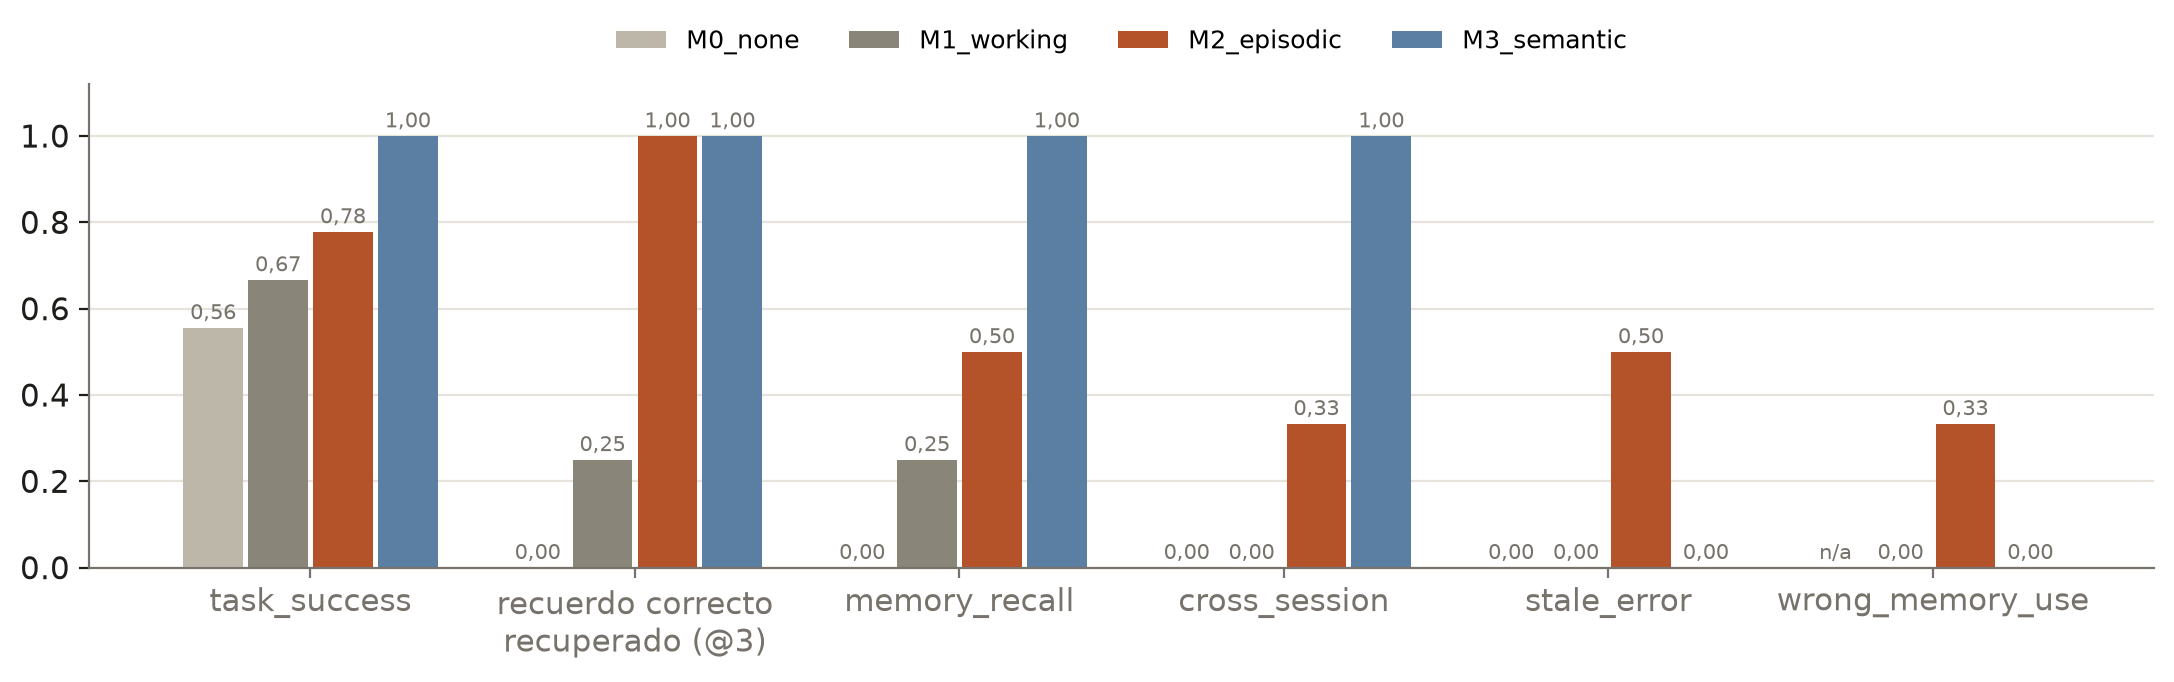

,id,status,superseded_by,origen,hecho
0,F001,active,,S1-1,"SPY risk signal as of 2023-03-13: severity medium (score 3; 5-day return -4.72%, 20-day volatility 15.79%, dra"
1,F002,superseded,F003,S2-1,"SPY risk signal as of 2024-08-05: severity medium (score 3; 5-day return -5.03%, 20-day volatility 19.19%, dra"
2,F003,active,,S2-2,"SPY risk signal as of 2024-08-30: severity low (score 1; 5-day return 0.28%, 20-day volatility 17.69%, drawdow"
3,F004,active,,S3-1,"SPY risk signal as of 2020-03-16: severity high (score 6; 5-day return -12.54%, 20-day volatility 76.95%, draw"
4,F005,active,,S3-2,"SPY risk signal as of 2025-04-08: severity high (score 6; 5-day return -11.5%, 20-day volatility 31.44%, drawd"


In [16]:
rd = RESULTS / "exp2" / "diagnostic_reader"
sumr = pd.read_csv(rd / "summary.csv"); perr = pd.read_csv(rd / "per_interaction.csv")
display(sumr.drop(columns=["context_tokens_mean", "memory_tokens_mean"]).round(3))
display(perr[perr.needs_memory | perr.stale_risk][["condition", "task_id", "task_success", "memory_shown", "memory_cited",
        "memory_recall_ok", "stale_error", "answer_as_of", "answer_severity"]])
display(Image(filename=str(ROOT / "slides" / "fig" / "exp2_metricas_lector.png")))
sem = read_jsonl(rd / "memory_store" / "M3_semantic" / "semantic.jsonl")
display(pd.DataFrame([{"id": m["memory_id"], "status": m["status"], "superseded_by": m.get("superseded_by", ""),
        "origen": m["provenance"]["interaction_id"], "hecho": m["text"][:110]} for m in sem]))

Con el lector determinista (`results/exp2/diagnostic_reader/`) el orden es claro: éxito **0,56 → 0,67 → 0,78 → 1,00** (M0 → M3).
* **M1** responde S1-2 (misma sesión) y nada entre sesiones (`cross_session_retention` 0).
* **M2** recupera entre sesiones (S1-3), pero en **S2-3 responde con el recuerdo obsoleto**: E004 (5-ago, *medium*) quedó primero (puntaje 2,40) sobre
  E005 (30-ago, *low*, 2,25): la importancia premia la alerta *medium* más que la recencia a la señal nueva. `stale_memory_error_rate` 0,5 y `wrong_memory_use_rate` 0,33. Guardar historia sin
  invalidarla es un riesgo real, no teórico.
* **M3** acierta las 4 que necesitan memoria (`memory_recall_accuracy` 1,0) porque el hecho del 5-ago quedó `superseded` por el del
  30-ago y ya no se sirve. En S3-3 distingue COVID de aranceles por similitud semántica.

La interferencia de S3-3 aparece con el agente y no con el lector: el ranking de M2 depende de los episodios escritos antes, que
cambian con la política. Es una fragilidad de la memoria episódica, no un resultado estable.

**Demostración rápida en vivo** (sin LLM): W0 sobre T09 y el borrado de un recuerdo persistido, en una copia del almacén.

In [17]:
# Demostracion en vivo sin LLM (rapida): W0 sobre T09 y borrado de un recuerdo en una copia del almacen M2
import shutil, tempfile
from tools import build_toolbox
from controller import run_task
from workflow import FixedPlanWorkflow
from memory import EpisodicStore
toolbox, retr = build_toolbox()
res = run_task(next(t for t in tasks if t["task_id"] == "T09"), FixedPlanWorkflow(), toolbox)
print("W0 en T09 ->", res["stop_reason"], [ (t["selected_tool"], (t.get("observation") or {}).get("code")) for t in res["trace"]])
tmp = Path(tempfile.mkdtemp()) / "ep.jsonl"; shutil.copy(RESULTS / "exp2" / "memory_store" / "M2_episodic" / "episodic.jsonl", tmp)
st = EpisodicStore(tmp); first = st.items[0]["memory_id"]
print("borrar", first, "->", st.delete(first), "| quedan", len(EpisodicStore(tmp).items), "recuerdos en disco")

W0 en T09 -> ABSTAIN [('search_evidence', None), ('compute_signal', 'date_not_trading_day'), ('finish', None)]
borrar E001 -> True | quedan 8 recuerdos en disco


## 6. Matriz de trazabilidad

| Sem. | Recurso estudiado | Concepto | Archivo / función | Evidencia de ejecución | Limitación propia |
|---|---|---|---|---|---|
| **9** | `Semana9/Lectura9-CC-0F4.md` (§2 pipeline/workflow/agente, §3 patrones, §5 Perceive-Decide-Act-Observe e invariantes, §6 ReAct, §8 límites y parada, §10 diseño experimental), `Semana9/Cuaderno9-CC-0F4.ipynb` (§13 controlador, §16 acciones permitidas, §18 ciclos y presupuestos), `Semana9/agent_loop.py`; Yao et al. (ReAct); Anthropic, *Building Effective Agents* | Workflow vs agente; ReAct; controlador con allowlist, presupuestos, detección de repetición y validación del `finish`; comparar contra baselines simples | `src/controller.py::run_task`, `check_finish`; `src/workflow.py::FixedPlanWorkflow`; `src/agent.py::QwenAgentPolicy`; `src/run_exp1.py` | W0 12/15 vs W1 1/15; 14 `REPEATED_ACTION`; 7/7 pruebas de robustez; 20 pruebas unitarias | Un solo modelo (0.5B); el deadline es cooperativo; la parada inmediata ante la primera repetición es estricta y explica parte del 1/15 |
| **10** | Enunciado PC3 §2 (Semana 10: working, episódica, semántica, procedimental, persistencia, invalidación); Park et al. (*Generative Agents*: relevancia + recencia + importancia); Packer et al. (*MemGPT*: contexto acotado frente a almacenamiento externo) | Estado de ejecución ≠ memoria; working vs episódica vs semántica; persistencia; versión, invalidación y borrado; procedencia | `src/memory.py` (`WorkingMemory`, `EpisodicStore`, `SemanticStore`); `src/run_exp2.py`; `tests/test_memory_eval.py` | Agente: recall 0 en M0–M3, recuerdo correcto mostrado 4/4 en M2; lector: 0,56 / 0,67 / 0,78 / 1,00, stale 0,5 en M2 y 0 en M3 | La memoria procedimental es solo el prompt fijo; 9 interacciones; el diagnóstico con lector se añadió tras ver resultados |
| 4 | `Semana4/Cuaderno4` (FAISS, e5) | Recuperación densa e índice | `SemanticStore` reutiliza el encoder e5 y `IndexFlatIP` | 5 hechos en M3 con el lector (1 invalidado) | Sin umbral de similitud: siempre devuelve algo (F001 servido sin ser pertinente) |
| 6 | `Semana6/Cuaderno6`, parcial Exp. 3 | Contratos, errores como datos, reintento selectivo y timeout | `src/tools.py` (`ARG_MODELS`, `ErrorObs`), `tool_risk.call_tool` del parcial | T11 `output_contract`, T12 `attempts=2`, R7 `TIMEOUT` | El timeout de la búsqueda es cooperativo (hilo) |
| 7 | `Semana7/Cuaderno7`, parcial Exp. 1 | Métricas con denominador explícito, análisis de errores | `src/evaluation.py` | `per_task.csv`, `per_interaction.csv`, trazas por tarea | 15 tareas y 9 interacciones: sin pruebas estadísticas |

## 7. Conclusiones y limitaciones

1. **¿Cuándo basta un workflow fijo?** Aquí, siempre: la tarea tiene pocas ramas previsibles. W0 resuelve 12/15 con 0 tokens. Sus 3
   fallos (evidencia no pertinente en T04 y T08, fecha no hábil en T09) se arreglan con reglas, no con autonomía.
2. **¿Cuándo aporta valor que el LLM controle las acciones?** Solo se vio en un paso intermedio: reformular la búsqueda (T04). Con un
   modelo de 0.5B ese valor no llega al resultado: 1/15 de éxito, ~21 veces más lento y ~3 000 tokens por tarea.
3. **¿Qué memoria mejora el desempeño?** Con el agente Qwen, ninguna: no usa los recuerdos (recall 0). Aislando la memoria, la
   semántica con versión e invalidación es la única sin errores (1,0). La episódica recupera entre sesiones, pero devuelve el recuerdo
   obsoleto (S2-3) y se confunde entre alertas parecidas (S3-3 con el agente).
4. **¿Cuándo la autonomía o la memoria aumentan el costo o el riesgo?** La autonomía multiplicó latencia y tokens sin ganar éxito. La
   memoria episódica sin invalidación introduce errores de obsolescencia. La semántica depende de su política de escritura: con un
   agente que casi no termina, quedó vacía y sirvió un hecho irrelevante.

**Lo que sostiene la seguridad es el controlador, no el modelo:** en 36 + 15 corridas del agente no salió ninguna alerta con severidad
inventada o evidencia no observada. Su límite: M0 S3-3 respondió con la alerta de SVB a una pregunta sobre el COVID. El controlador
verifica que lo dicho esté sustentado, no que responda a la pregunta.

**Limitaciones.** Un solo LLM (0.5B, CPU, greedy). 15 tareas y 9 interacciones: resultados descriptivos, sin significancia. Benchmark y
evidencia anotados por el autor. El prompt se ajustó con 2 tareas de desarrollo. El diagnóstico con lector determinista y las métricas
`gold_retrieved_*` se añadieron **después** de ver la corrida con Qwen (declarado). Parar ante la primera repetición es una decisión
estricta del controlador: con una política más tolerante W1 quizá habría terminado más tareas, pero no se probó para no cambiar los
límites tras ver los resultados. Las fallas inyectadas son controladas, no de red real. La memoria procedimental no se evaluó.